# 2024TSA Pooled GWAS


- How does association evidence compare when the two breeds are combined?
- Effect and score meta-analysis, Fisher’s method, and exploratory pooled models use shared measured markers from LR and GSP under both control schemes.
- These methods summarize combined evidence, effect direction, and between-breed heterogeneity under their respective assumptions.
- They do not provide independent replication or establish that an effect is shared between breeds.

### (Initialization) Import Directory-Free Helpers


### (Data Matching) Match Shared Variants (Scheme A)
- Markers must share identifier, CanFam4 position and REF/ALT alleles, and pass frequency filtering in each breed.
- Between-breed independence is assumed, not proven by different identifiers.
- Cutoffs use 0.05 divided by shared candidates, without correction across methods or tests.
- *cross_breed_meta.py*

In [1]:
# Load the cross-breed settings and reuse or rebuild meta-analysis summaries from saved within-breed fits.
# Check their provenance and native verification before displaying the shared-marker analysis families.

from pathlib import Path
import importlib
import sys
study_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/notebook_support.py").exists())
sys.path.insert(0, str(study_root / "scripts"))
read_json = importlib.import_module("notebook_support").read_json
file_digest = importlib.import_module("notebook_support").file_digest
require_saved = importlib.import_module("notebook_review").require_saved
run_script = importlib.import_module("notebook_support").run_script
from IPython.display import Markdown, Image, display

def scheme_label(value):
    return {"success-vs-behelim": "A", "not-behelim-vs-behelim": "B"}[value]
import os, subprocess
meta_folder = study_root / "results/private/version2/08_cross_breed"
pooled_run = study_root / "data/07-gwas/pooled-measured-20261004"
pooled_folder = meta_folder / "pooled"
configuration = read_json(study_root / "config/cross_breed.json")

# Set True to rebuild summaries from the saved breed-specific fits.
# This verifies native output receipts and can take several minutes.
rebuild_meta = False
require_saved(meta_folder / "summary.private.json")
require_saved(meta_folder / "verification.private.json")
# if rebuild_meta or not (meta_folder / "summary.private.json").exists():
#     run_script(study_root, "cross_breed_meta.py", "--results-dir", meta_folder)
if rebuild_meta:
    if os.name == "nt":
        raise RuntimeError("Use the WSL/Linux project kernel for native R verification.")
    association_r = Path.home() / "anaconda3/envs/tsa2024-association/bin/Rscript"
#     subprocess.run([str(association_r), str(study_root / "scripts/check_cross_breed.R"), str(study_root)], check=True)
meta = read_json(meta_folder / "summary.private.json")
assert meta["status"] == "cross_breed_meta_complete"
assert meta["config_sha256"] == file_digest(study_root / "config/cross_breed.json")
assert meta["script_sha256"] == file_digest(study_root / "scripts/cross_breed_meta.py")
assert meta["original_sources_unchanged"]
lines = ['| Scheme | Shared Candidates | Tested In Both Breeds | Cutoff | Unavailable Effect Pairs |',
         "| :---: | :---: | :---: | :---: | :---: |"]
for r in meta["families"]:
    lines.append(f"| {scheme_label(r['scenario'])} | {r['common_candidates']:,} | {r['eligible_both']:,} | {r['threshold']:.3g} | {r['invalid_effect_pairs']} |")
display(Markdown("\n".join(lines)))

| Scheme | Shared Candidates | Tested In Both Breeds | Cutoff | Unavailable Effect Pairs |
| :---: | :---: | :---: | :---: | :---: |
| A | 157,217 | 155,219 | 3.18e-07 | 11 |
| B | 157,217 | 157,217 | 3.18e-07 | 8 |

### (Meta-Analysis) Combine GEMMA Effects
- Inverse-variance weighting favors more precise effects.
- Results retain breed effects, weights, uncertainty and heterogeneity, which is imprecise with two breeds.
- Linear effects on binary outcomes depend on case fractions.
- Combined effects are sensitivity summaries, not pooled odds ratios or population risks.

| Scheme | Analysis | Valid Tests | Below Cutoff | Minimum P |
| :---: | :---: | :---: | :---: | :---: |
| A | GEMMA inverse variance | 155,208 | 24 | 1.91e-12 |
| B | GEMMA inverse variance | 157,209 | 29 | 1.64e-13 |

### Scheme A: effect estimates

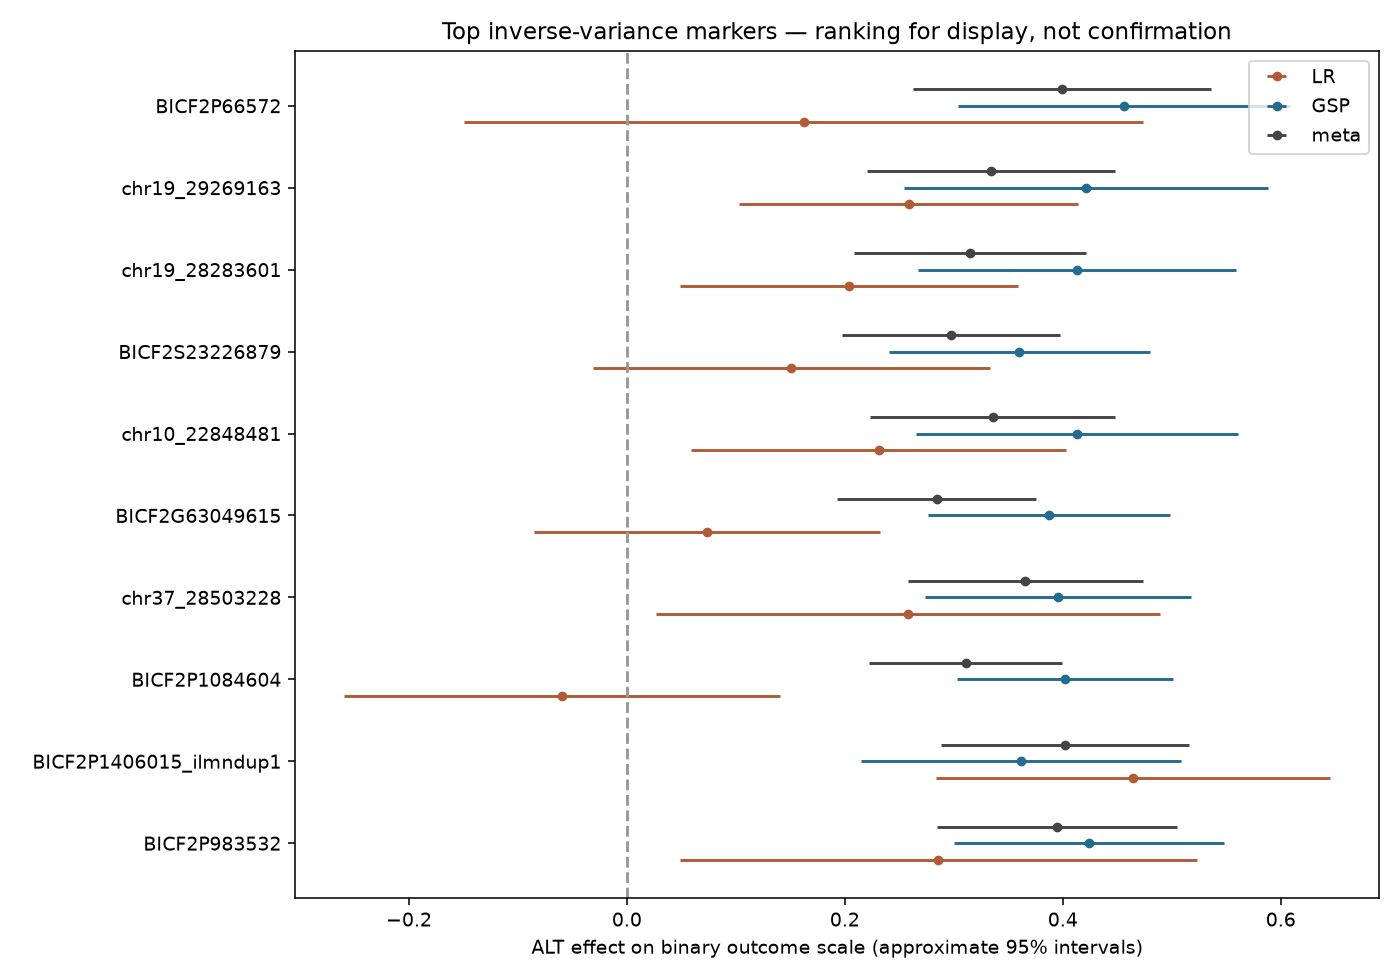

### Scheme B: effect estimates

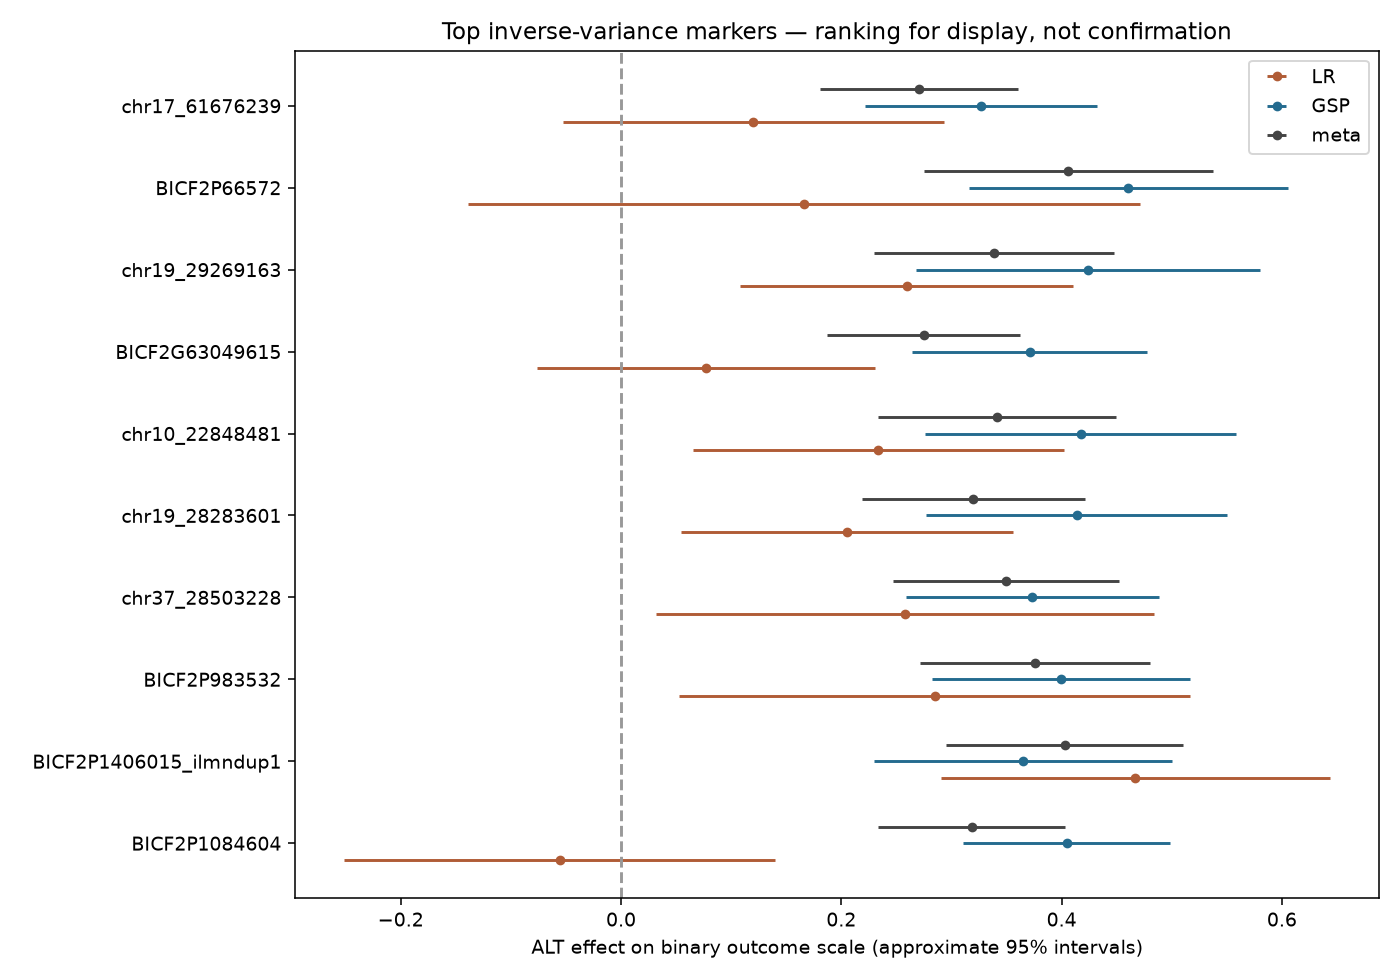

In [2]:
# Define inverse-variance effect combination and display its saved results for each control scheme.
# Effects must use the same allele and scale; the weights reflect their estimated uncertainty.

import numpy as np
from scipy.stats import norm

def inverse_variance_effect(effects, standard_errors):
    """Combine effects expressed for the same allele on the same scale."""
    effects = np.asarray(effects, dtype=float)
    standard_errors = np.asarray(standard_errors, dtype=float)
    if not np.isfinite(effects).all() or not np.isfinite(standard_errors).all() or (standard_errors <= 0).any():
        raise ValueError("Both effects need finite, positive standard errors.")
    weights = 1 / standard_errors**2
    combined = np.sum(weights * effects) / weights.sum()
    error = np.sqrt(1 / weights.sum())
    probability = 2 * norm.sf(abs(combined / error))
    return combined, error, probability

def show_analysis_rows(records):
    lines = ['| Scheme | Analysis | Valid Tests | Below Cutoff | Minimum P |',
             '| :---: | :---: | :---: | :---: | :---: |']
    for r in records:
        lines.append(f"| {scheme_label(r['scenario'])} | {r['analysis']} | {r['valid_tests']:,} | {r['below_cutoff']} | {r['minimum_p']:.3g} |")
    display(Markdown("\n".join(lines)))

show_analysis_rows([r for r in meta["analyses"] if r["p_column"] == "iv_p"])
for family in meta["families"]:
    display(Markdown("### " + "Scheme " + scheme_label(family["scenario"]) + ": effect estimates"))
    display(Image(filename=str(meta_folder / (family["scenario"] + "_effects.png"))))

In [3]:
# Display the ten smallest valid primary meta-analysis probabilities with breed effects and heterogeneity.
# This shows whether a combined result is dominated by one breed or has opposing effect directions.

import csv, gzip
with gzip.open(meta_folder / (configuration["primary_scheme"] + ".private.tsv.gz"), "rt", encoding="utf-8") as handle:
    primary_meta = list(csv.DictReader(handle, delimiter="\t"))
top_effects = sorted((r for r in primary_meta if np.isfinite(float(r["iv_p"]))), key=lambda r: float(r["iv_p"]))[:10]
lines = ['| CanFam4 Marker | CanFam4 Position | ALT | LR Effect | GSP Effect | LR Weight | Q P | I² | Same Direction |',
         '| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |']
for r in top_effects:
    lines.append(f"| {r['marker']} | chr{r['chromosome']}:{r['position']} | {r['ALT']} | {float(r['LR_GEMMA_beta']):.3g} | {float(r['GSP_GEMMA_beta']):.3g} | {float(r['LR_weight_fraction']):.1%} | {float(r['Q_p']):.3g} | {float(r['I2']):.1%} | {r['same_effect_direction']} |")
display(Markdown("\n".join(lines)))

| CanFam4 Marker | CanFam4 Position | ALT | LR Effect | GSP Effect | LR Weight | Q P | I² | Same Direction |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| BICF2P983532 | chr37:28424522 | C | 0.286 | 0.424 | 21.4% | 0.311 | 2.6% | True |
| BICF2P1406015_ilmndup1 | chr1:118539020 | C | 0.464 | 0.361 | 39.7% | 0.387 | 0.0% | True |
| BICF2P1084604 | chr17:59758927 | T | -0.0595 | 0.402 | 19.7% | 5.02e-05 | 93.9% | False |
| chr37_28503228 | chr37:28389741 | C | 0.258 | 0.396 | 21.8% | 0.303 | 5.7% | True |
| BICF2G63049615 | chr19:29781532 | T | 0.0737 | 0.387 | 32.9% | 0.0015 | 90.1% | True |
| chr10_22848481 | chr10:23805403 | T | 0.231 | 0.413 | 42.5% | 0.116 | 59.5% | True |
| BICF2S23226879 | chr2:76618161 | T | 0.151 | 0.36 | 30.1% | 0.0596 | 71.8% | True |
| chr19_28283601 | chr19:29696181 | A | 0.204 | 0.413 | 46.8% | 0.054 | 73.1% | True |
| chr19_29269163 | chr19:30683632 | T | 0.259 | 0.421 | 53.6% | 0.163 | 48.6% | True |
| BICF2P66572 | chr1:46541651 | T | 0.162 | 0.456 | 19.3% | 0.0964 | 63.8% | True |

### (Meta-Analysis) Combine GMMAT Scores
- Scores and information variances are summed across breeds and checked against native GMMAT meta-analysis.
- Opposing effects can cancel.
- Results are not combined with GEMMA.

In [4]:
# Display the separate GMMAT score meta-analysis and require the independent native verification to pass.
# GMMAT evidence remains separate from the GEMMA effect analysis.

show_analysis_rows([r for r in meta["analyses"] if r["p_column"] == "score_meta_p"])
# Native verification also independently checks all GEMMA effect and Fisher calculations in R.
verification = read_json(meta_folder / "verification.private.json")
assert verification["status"] == "all_cross_breed_meta_calculations_verified"
verification["checks"]

| Scheme | Analysis | Valid Tests | Below Cutoff | Minimum P |
| :---: | :---: | :---: | :---: | :---: |
| A | GMMAT score meta | 155,219 | 0 | 4.39e-06 |
| B | GMMAT score meta | 157,217 | 0 | 2.62e-06 |

{'success-vs-behelim': {'markers': 155219,
  'native_gmmat_score_meta_verified': True,
  'effect_meta_verified': True,
  'fisher_verified': True},
 'not-behelim-vs-behelim': {'markers': 157217,
  'native_gmmat_score_meta_verified': True,
  'effect_meta_verified': True,
  'fisher_verified': True}}

### (Evidence Combination) Fisher’s Combined Evidence
- Fisher's method combines probabilities without requiring matching directions.
- One breed or opposing effects can drive a strong result.
- Each method and test type remains separate.

| Scheme | Analysis | Valid Tests | Below Cutoff | Minimum P |
| :---: | :---: | :---: | :---: | :---: |
| A | GEMMA Wald Fisher | 155,208 | 17 | 4.2e-11 |
| A | GEMMA likelihood ratio Fisher | 155,219 | 4 | 5.15e-08 |
| A | GEMMA score Fisher | 155,219 | 0 | 2.78e-06 |
| A | GMMAT score Fisher | 155,219 | 0 | 1.61e-05 |
| B | GEMMA Wald Fisher | 157,209 | 23 | 2.07e-12 |
| B | GEMMA likelihood ratio Fisher | 157,217 | 3 | 7.82e-10 |
| B | GEMMA score Fisher | 157,217 | 0 | 4.48e-06 |
| B | GMMAT score Fisher | 157,217 | 0 | 9.97e-06 |

### Scheme A: combined evidence

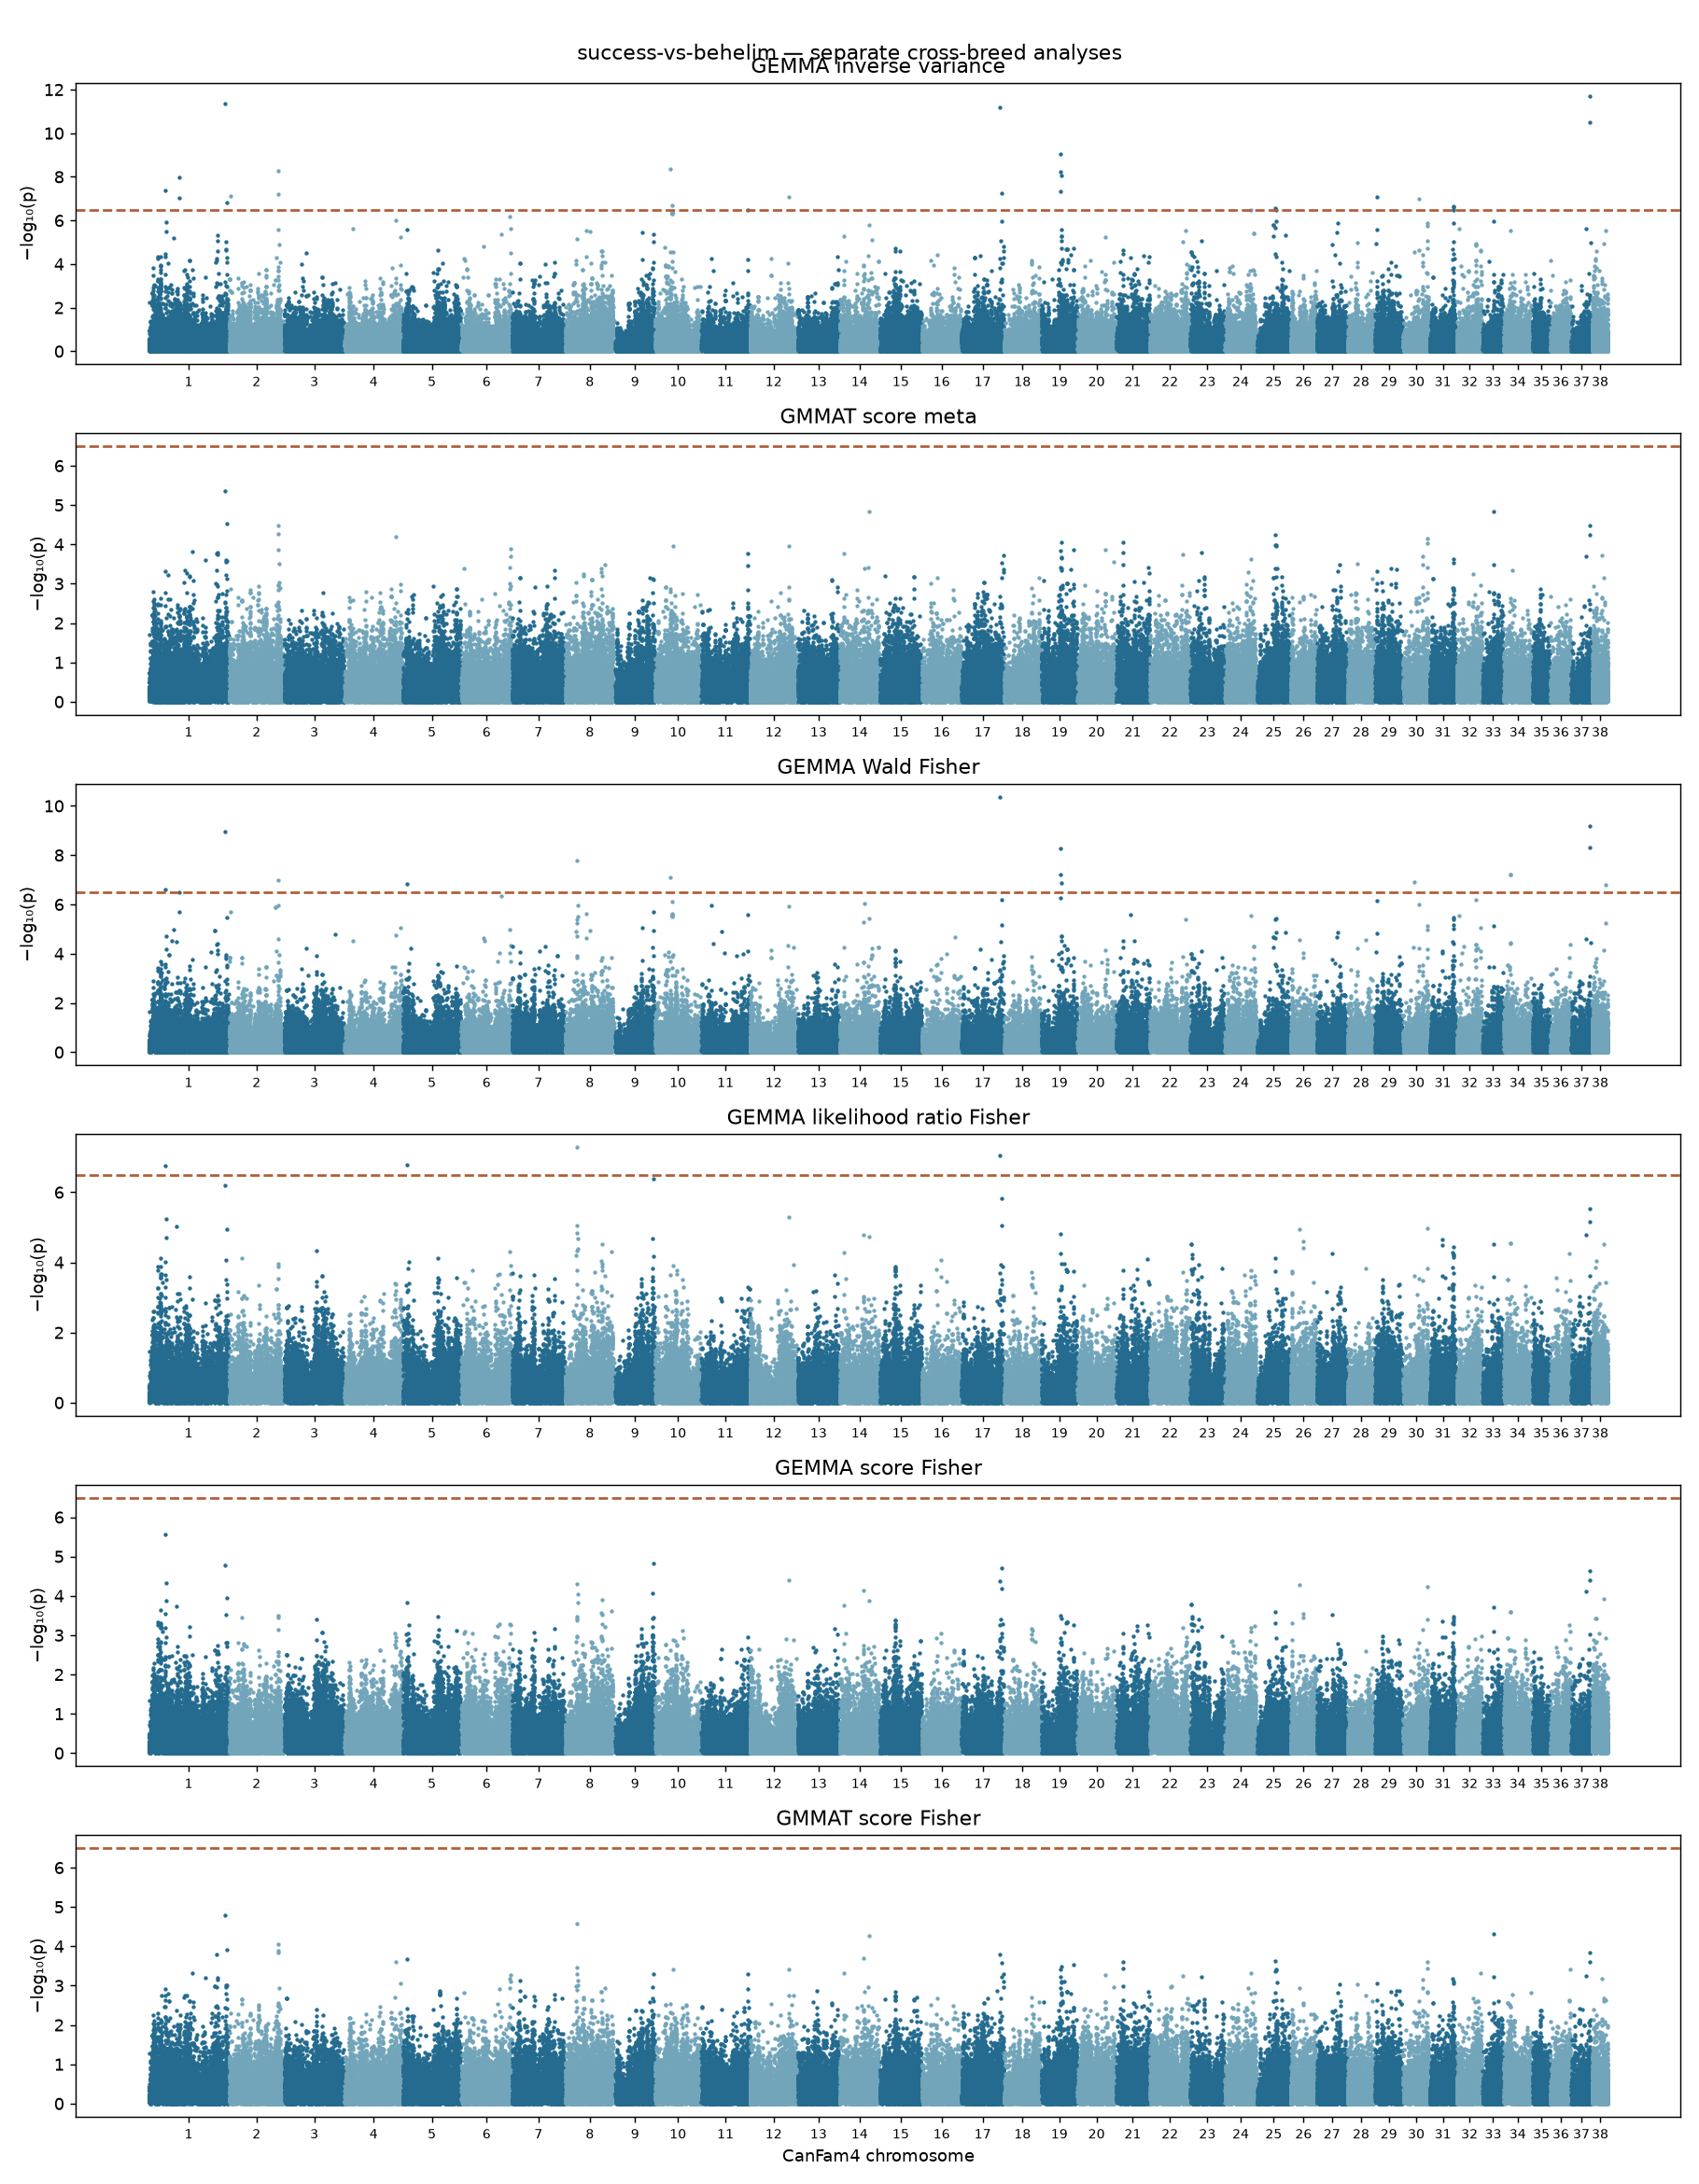

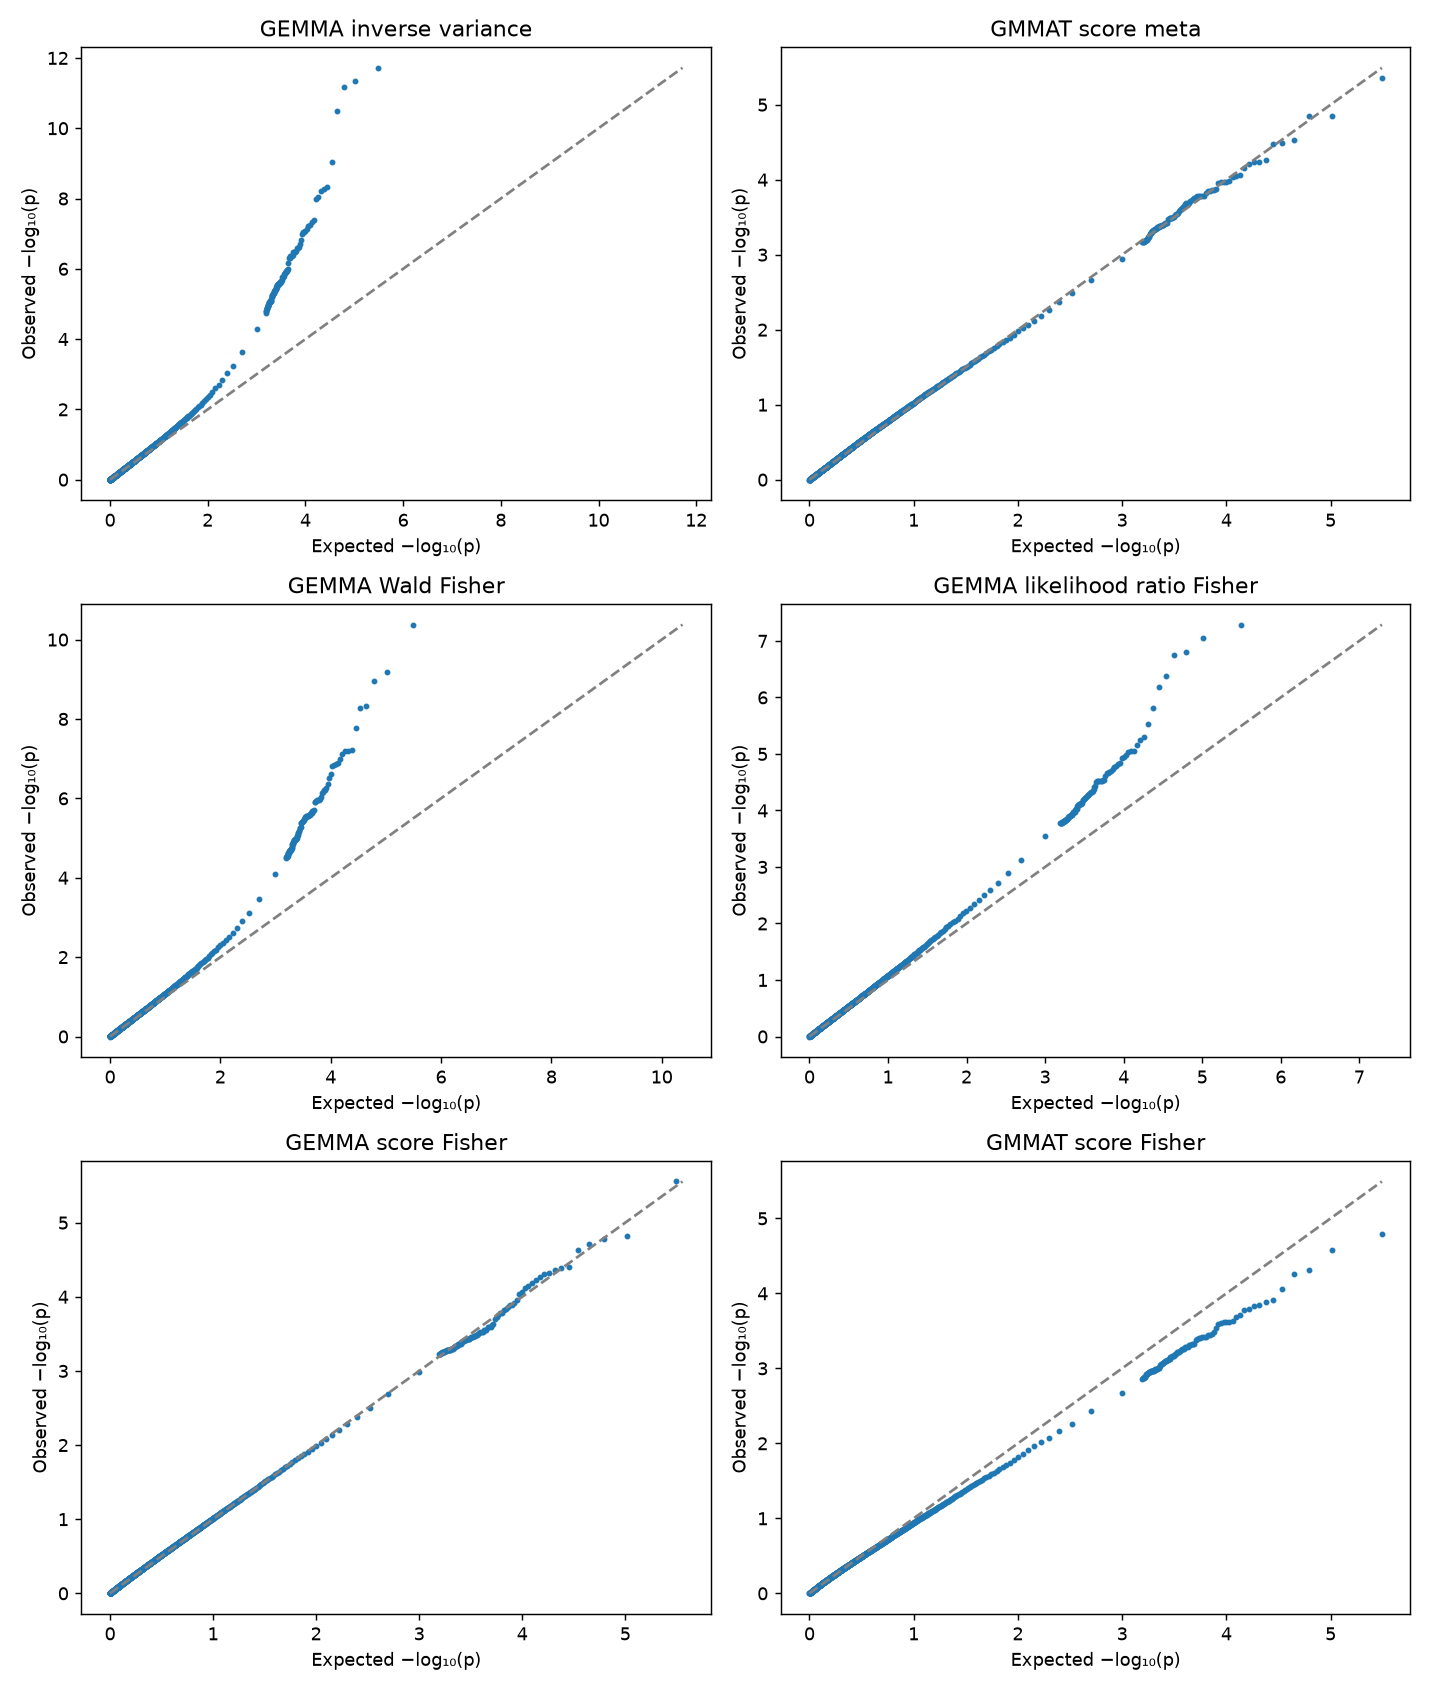

### Scheme B: combined evidence

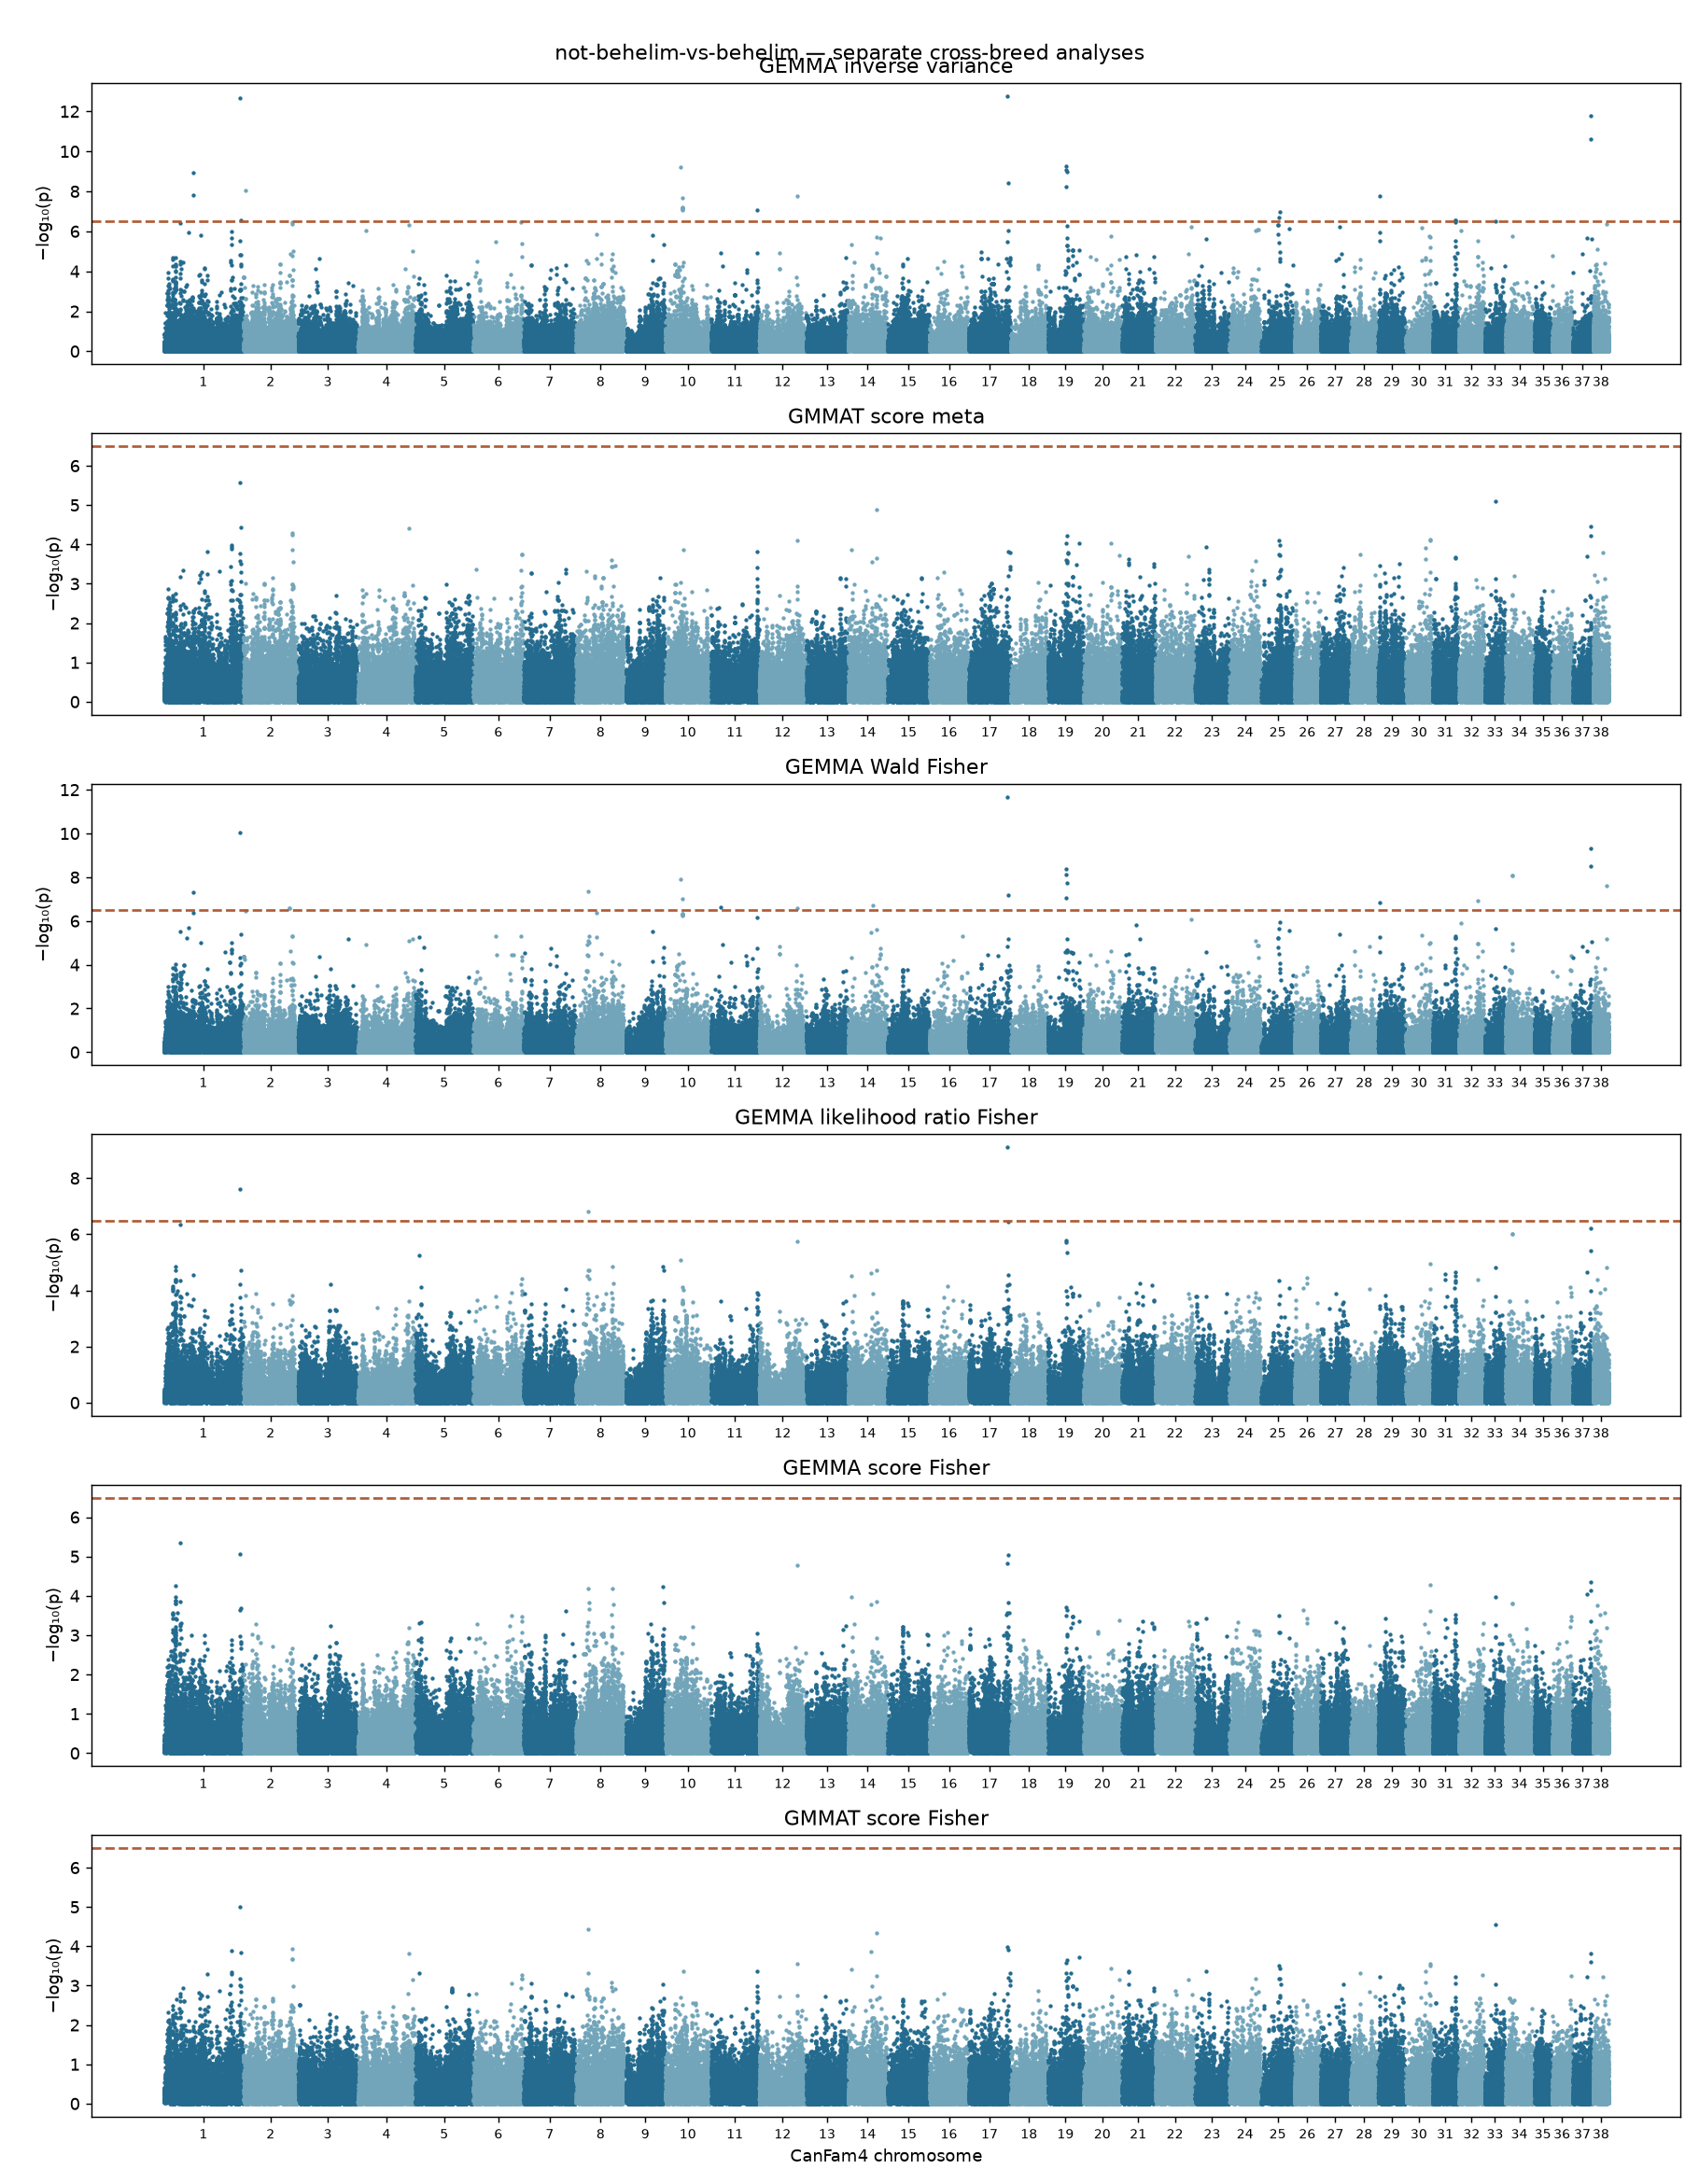

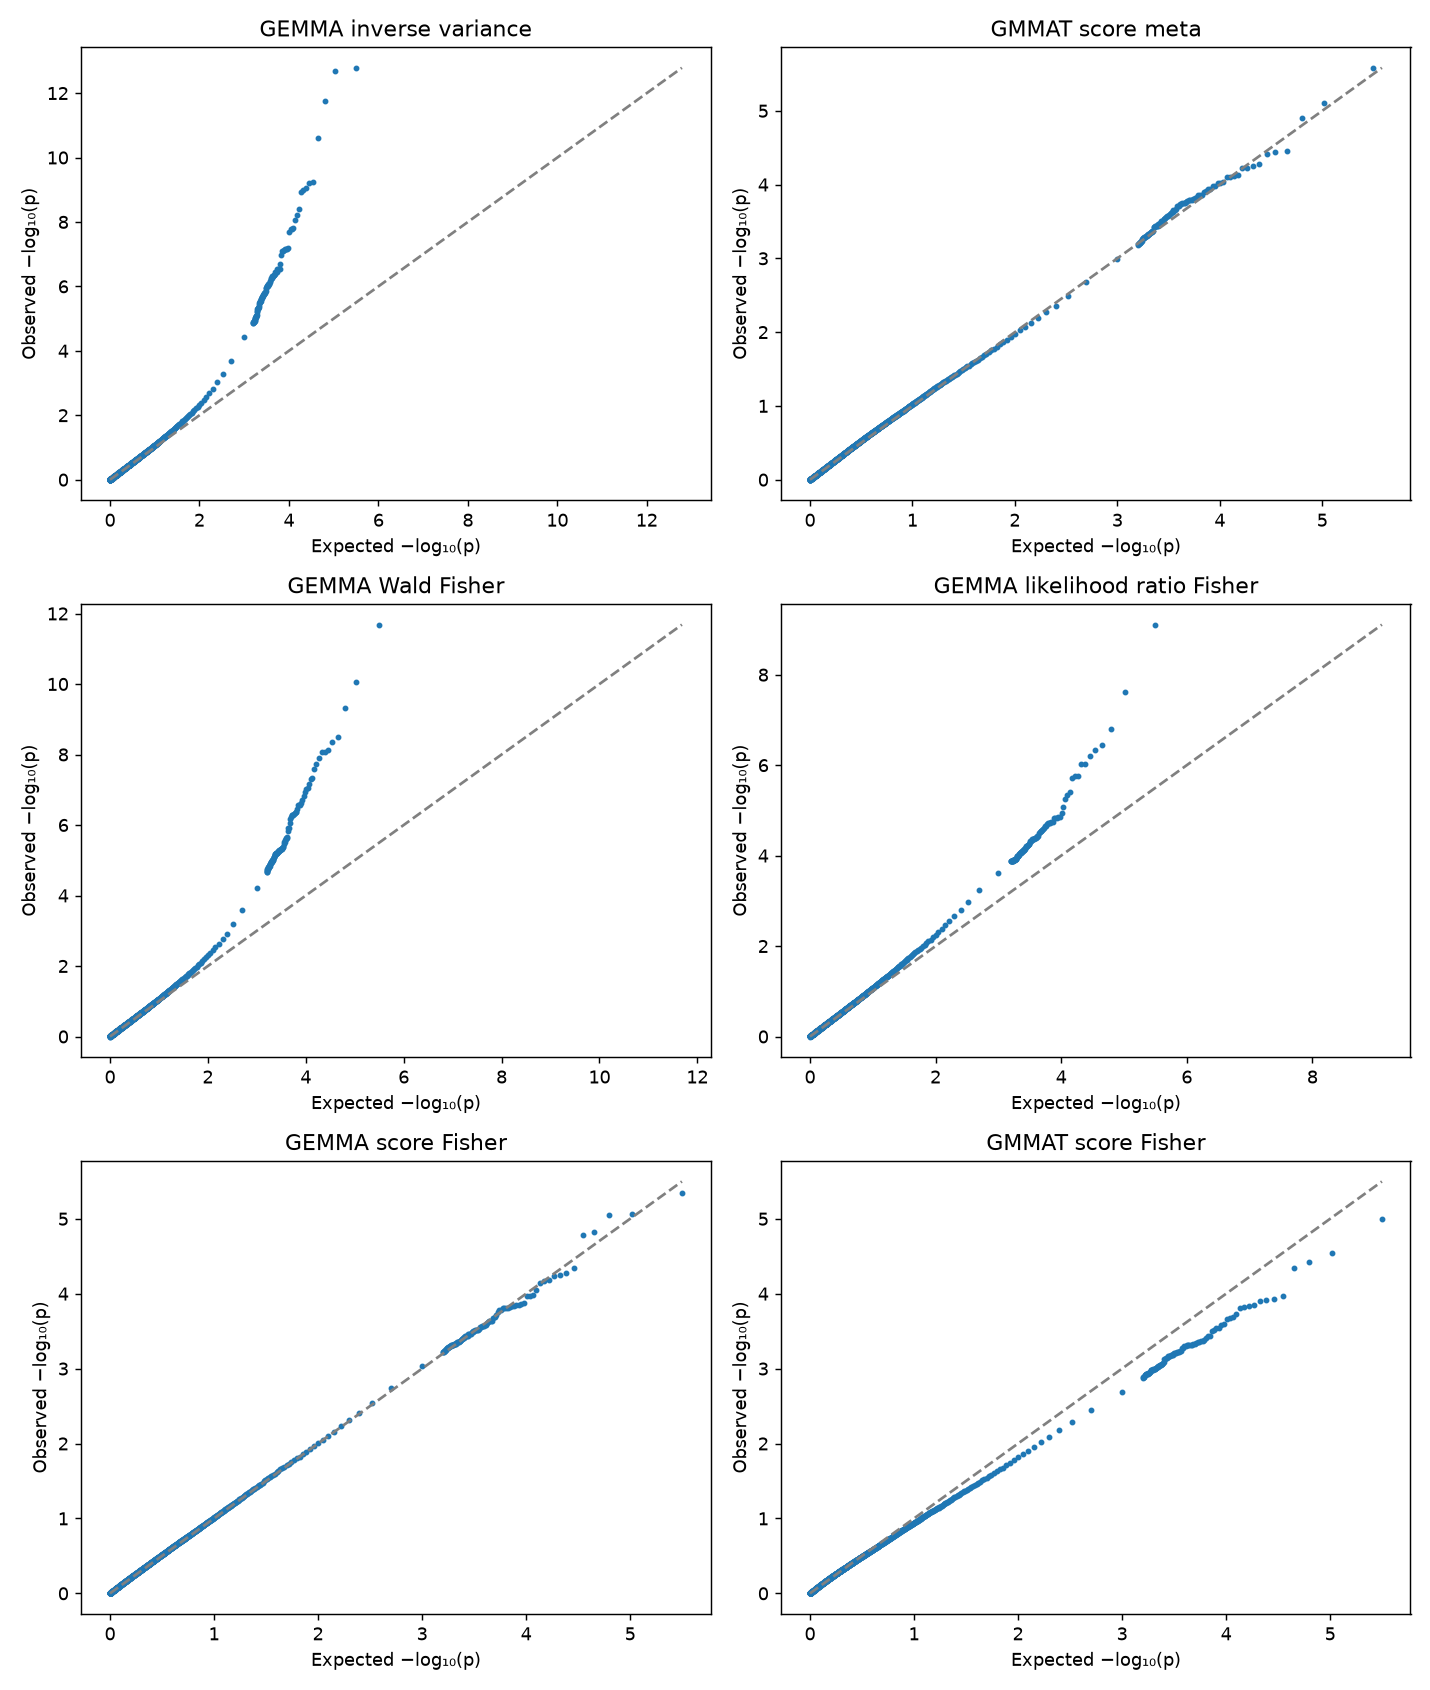

In [5]:
# Define Fisher's probability combination and display the saved method-specific results and plots.
# This scheme combines association evidence without requiring matching effect directions.

from scipy.stats import chi2

def fishers_probability(probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    if not np.isfinite(probabilities).all() or ((probabilities <= 0) | (probabilities > 1)).any():
        raise ValueError("Fisher's method needs finite probabilities in (0, 1].")
    return chi2.sf(-2 * np.log(probabilities).sum(), 2 * len(probabilities))

show_analysis_rows([r for r in meta["analyses"] if r["p_column"].endswith("_fisher")])
for family in meta["families"]:
    display(Markdown("### " + "Scheme " + scheme_label(family["scenario"]) + ": combined evidence"))
    for suffix in ["_manhattan.png", "_qq.png"]:
        display(Image(filename=str(meta_folder / (family["scenario"] + suffix))))

### (Association Testing) Exploratory Pooled Models
- Models adjust for breed and sex using shared measured markers.
- Missing values use their breed/group mean.
- The joint relationship matrix uses within-breed standardization and one genetic variance component, an exploratory assumption.
- Publication inclusion remains undecided.
- *pooled_gwas.py*
- *check_pooled_inputs.py*
- *summarize_pooled.py*

| Scheme | Analysis | Valid Tests | Below Cutoff | Minimum P |
| :---: | :---: | :---: | :---: | :---: |
| A | GEMMA Wald | 155,219 | 9 | 9.68e-12 |
| A | GEMMA likelihood ratio | 155,219 | 3 | 7.04e-08 |
| A | GEMMA score | 155,219 | 0 | 8.58e-07 |
| A | GMMAT score | 155,219 | 0 | 1.36e-05 |
| B | GEMMA Wald | 157,217 | 12 | 7.21e-13 |
| B | GEMMA likelihood ratio | 157,217 | 3 | 2.61e-08 |
| B | GEMMA score | 157,217 | 0 | 3.57e-07 |
| B | GMMAT score | 157,217 | 0 | 8.09e-06 |

| Scheme | Converged GMMAT Chromosome Nulls | GEMMA ML Variance-Boundary Markers | Median χ² Ratio, Wald / GMMAT Score |
| :---: | :---: | :---: | :---: |
| A | 38/38 | 155,219 | 1.050 / 1.022 |
| B | 38/38 | 157,217 | 1.047 / 1.024 |

### Scheme A: 151 dogs, 16 cases

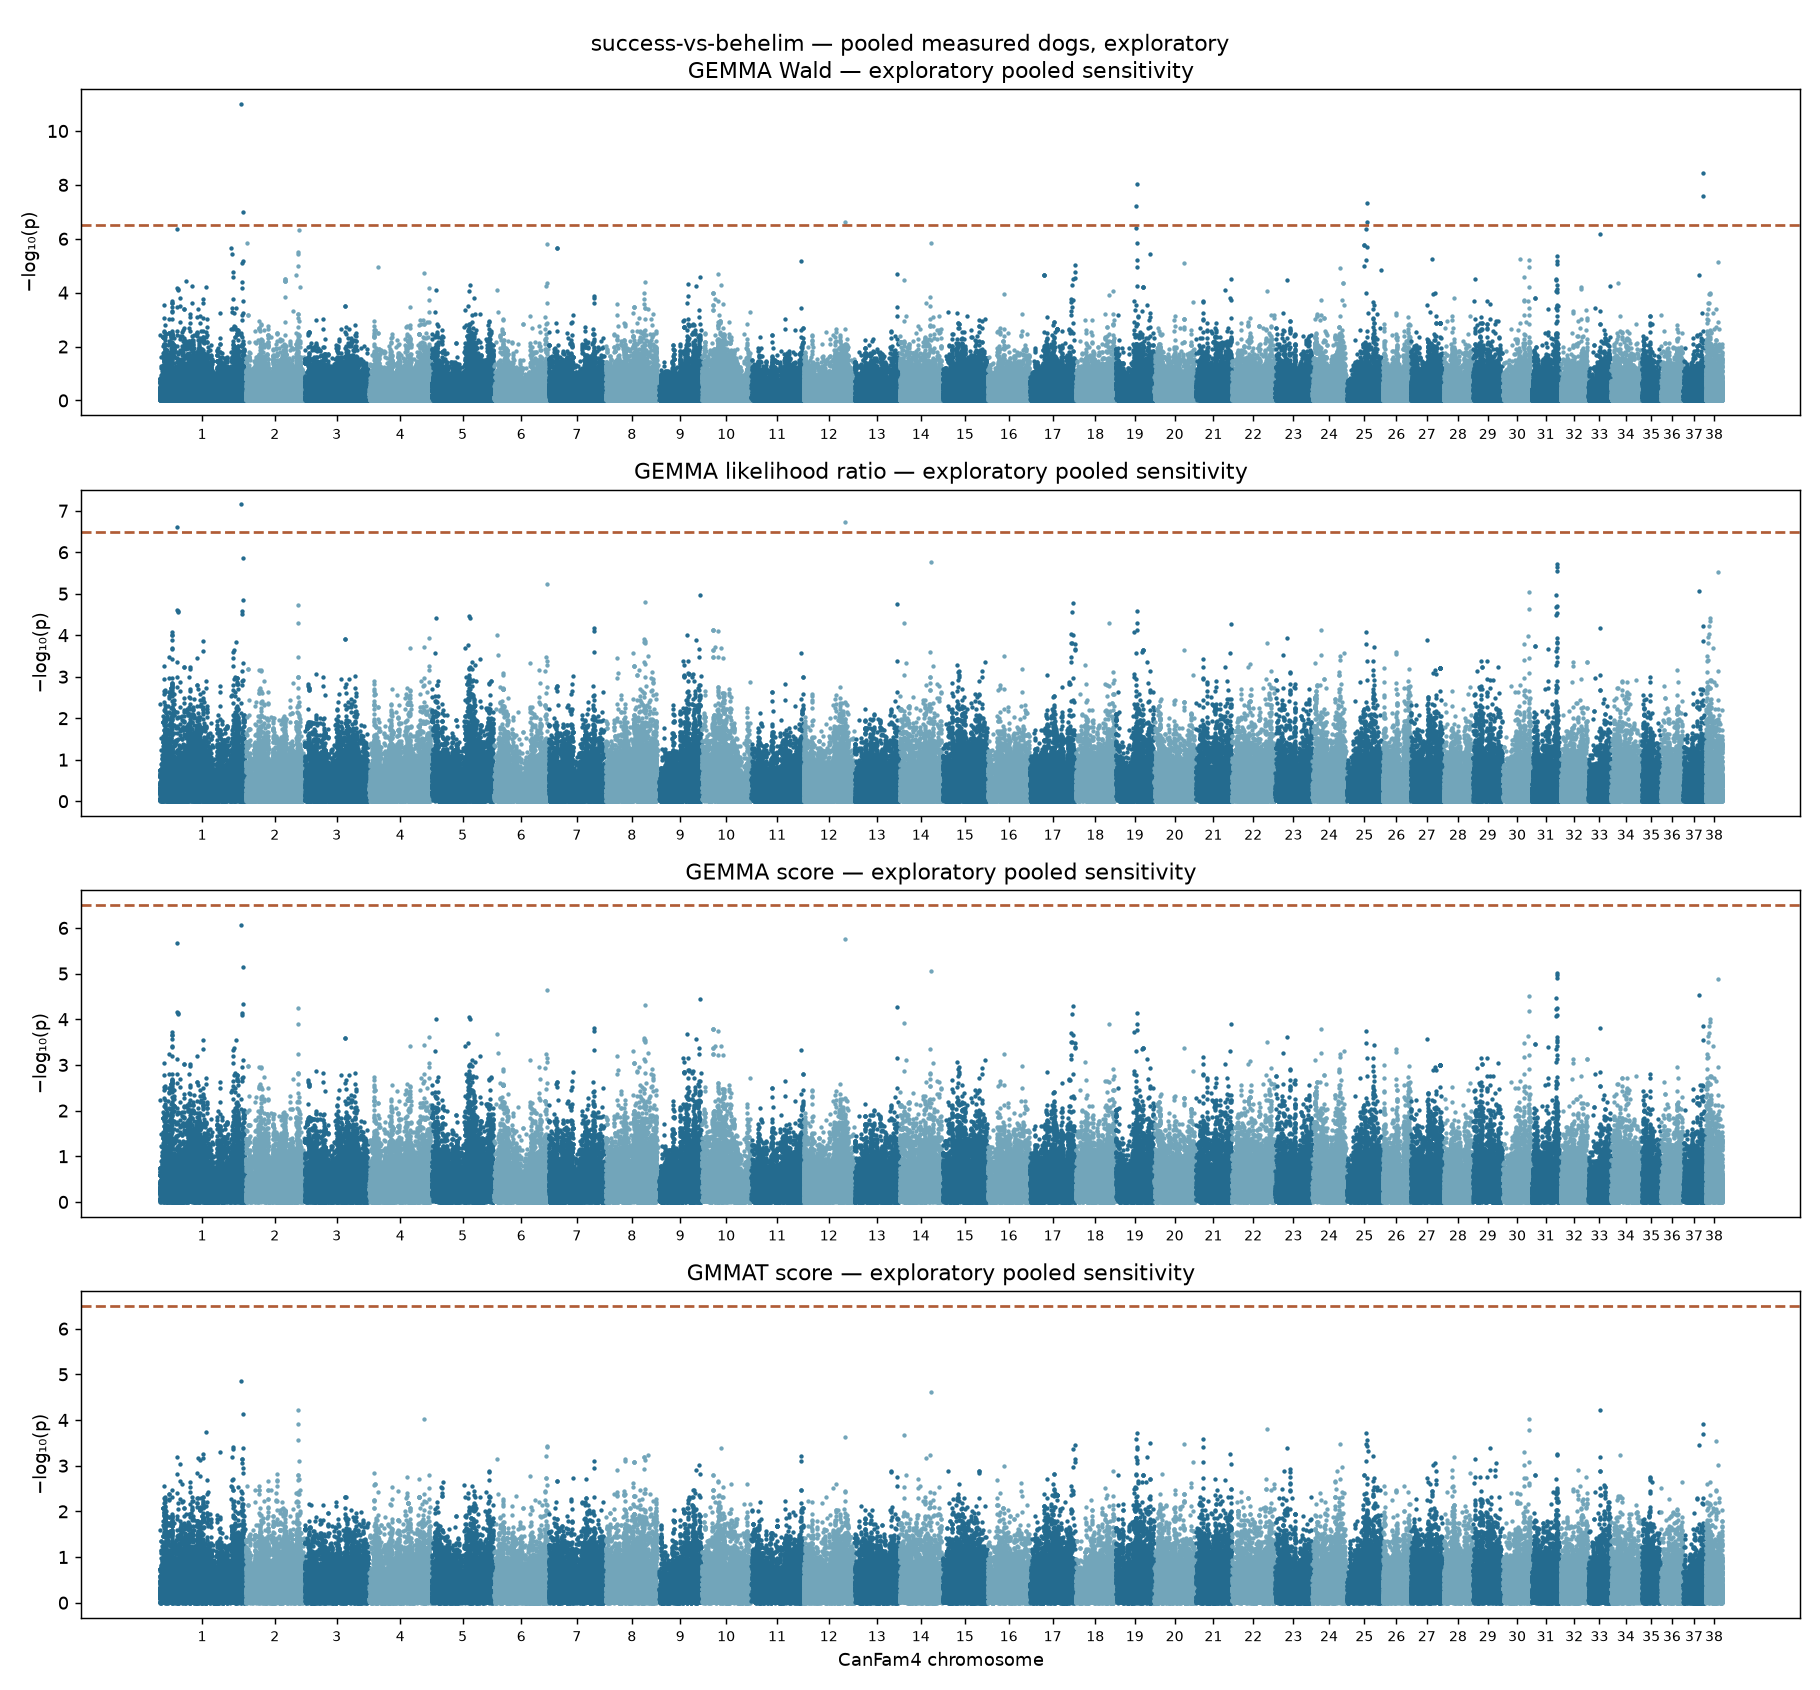

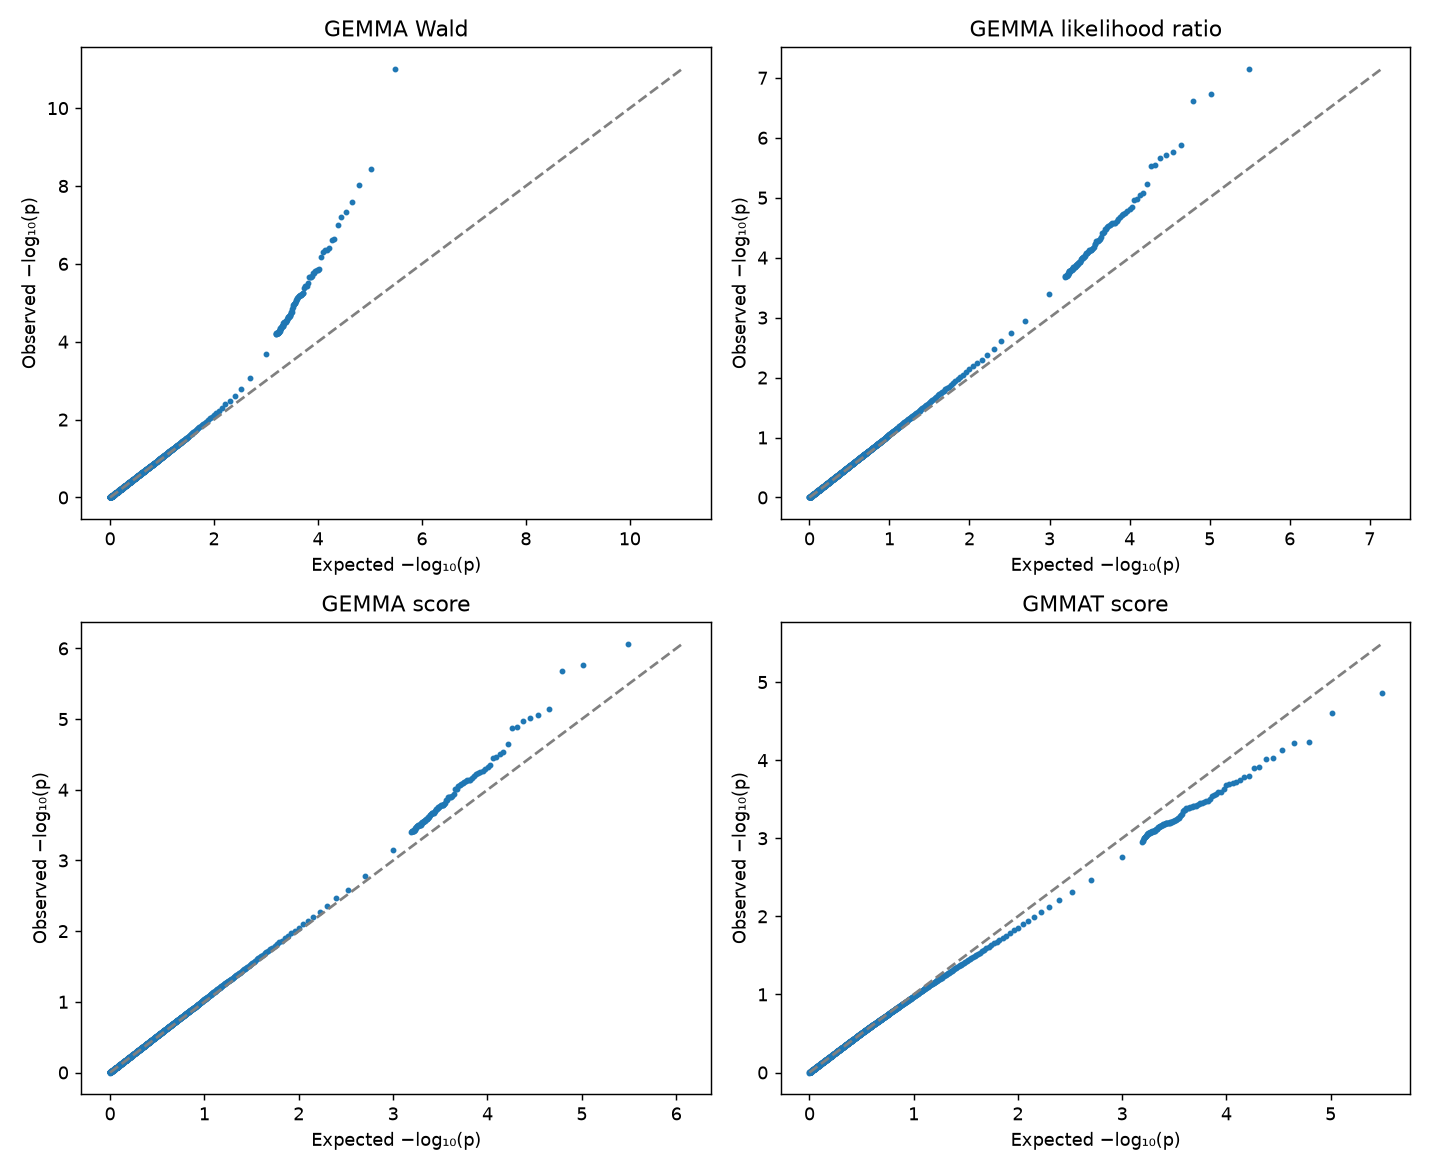

### Scheme B: 164 dogs, 16 cases

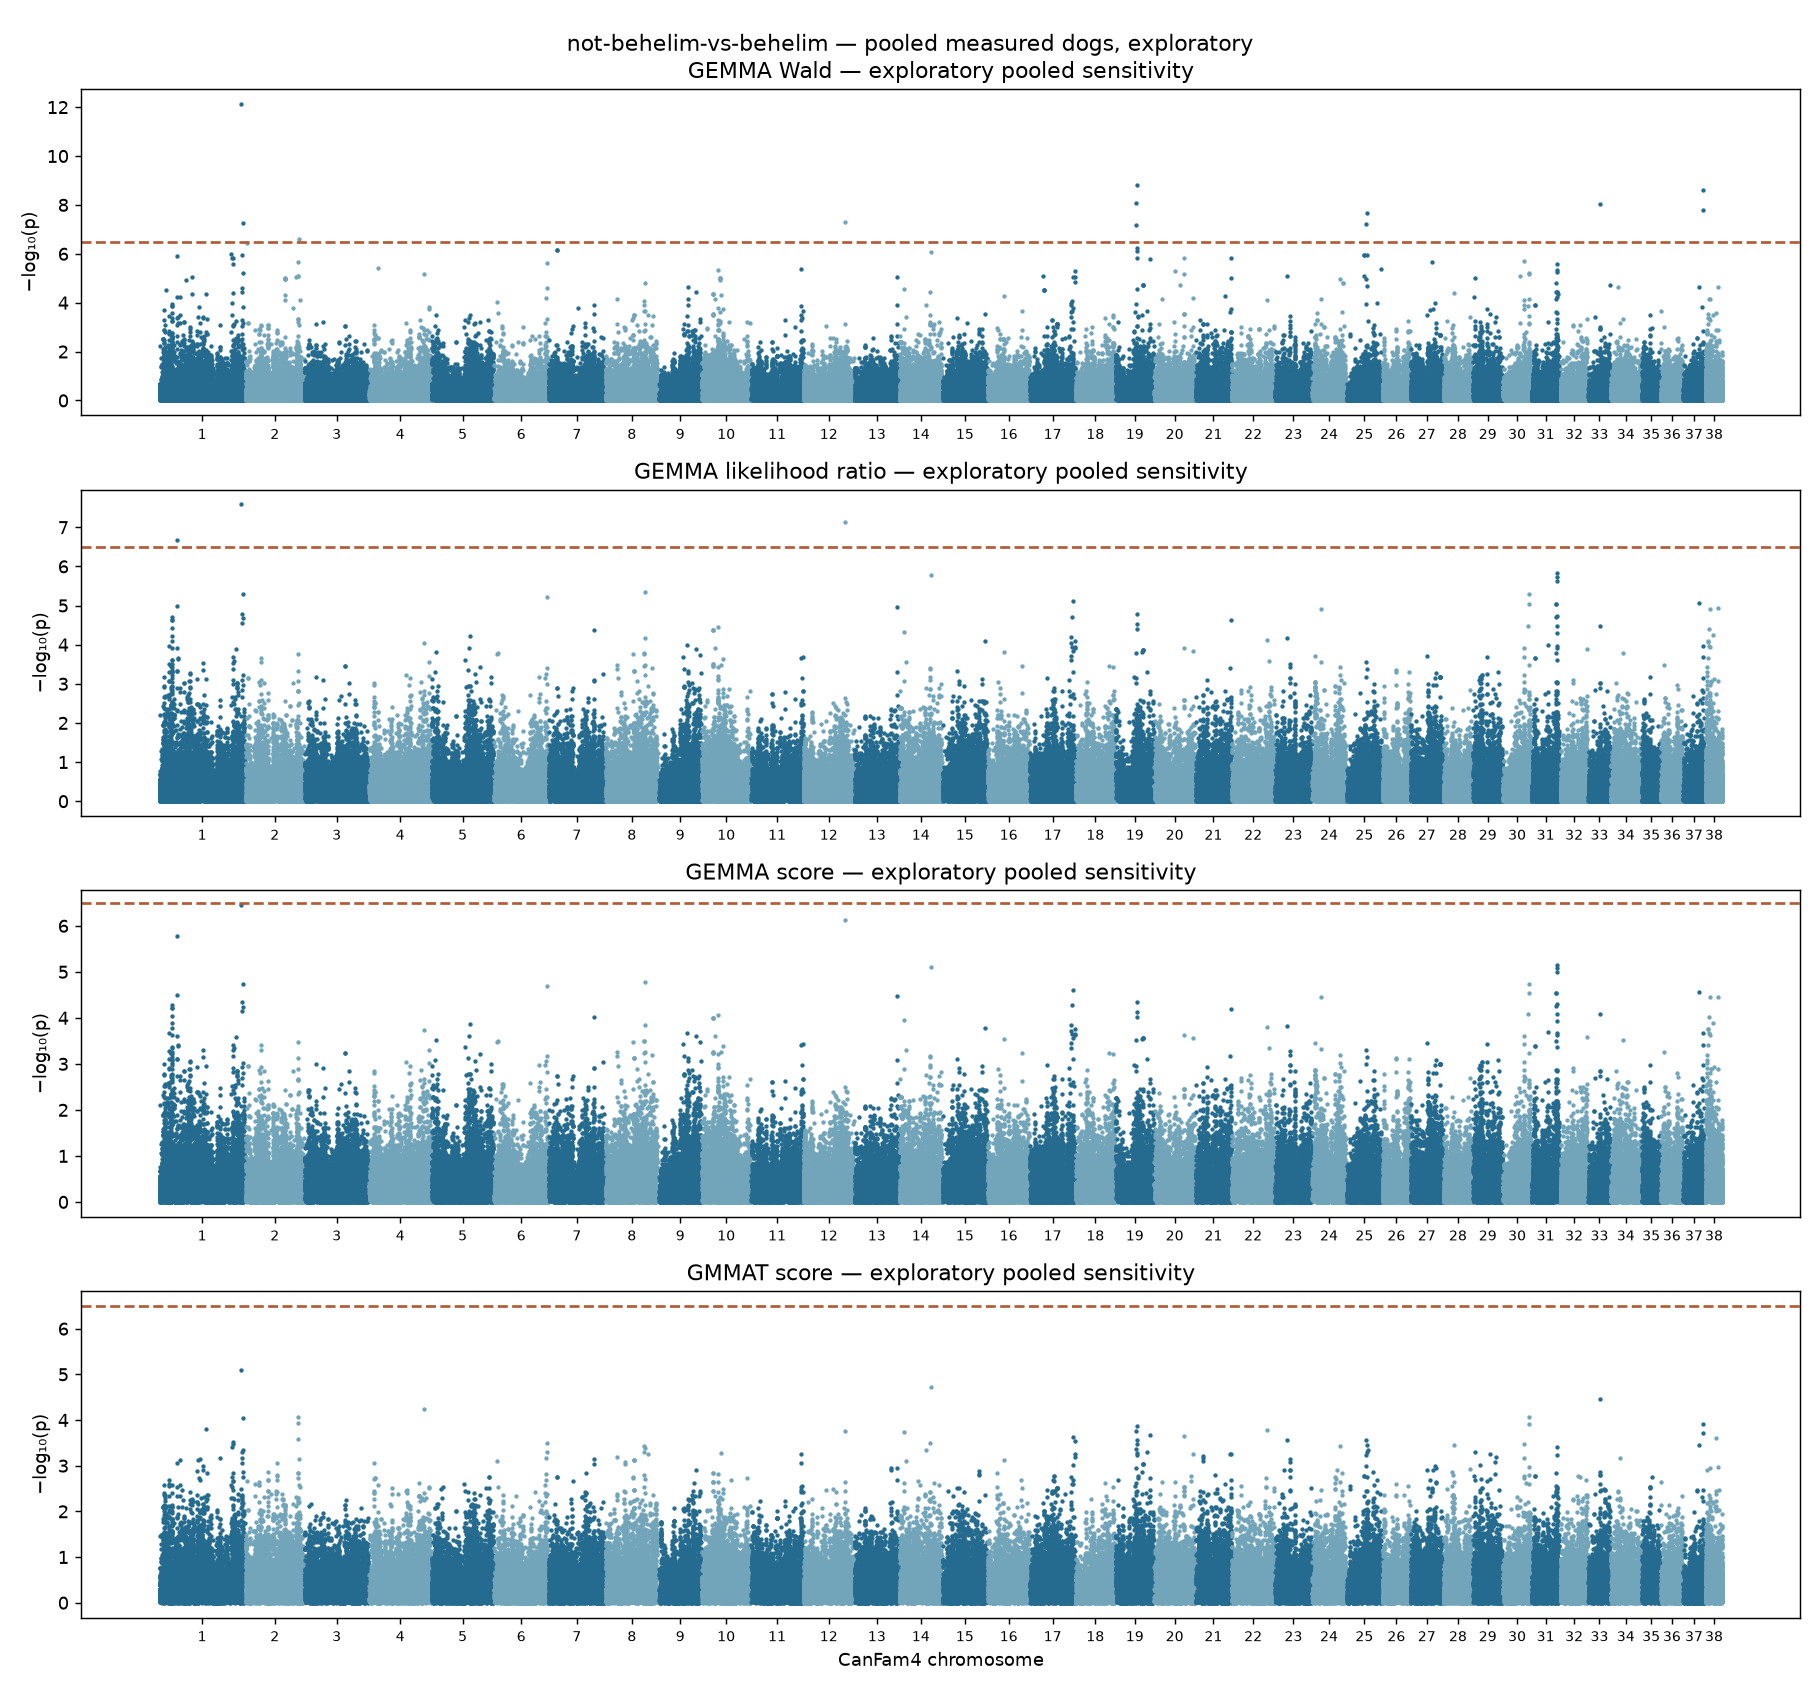

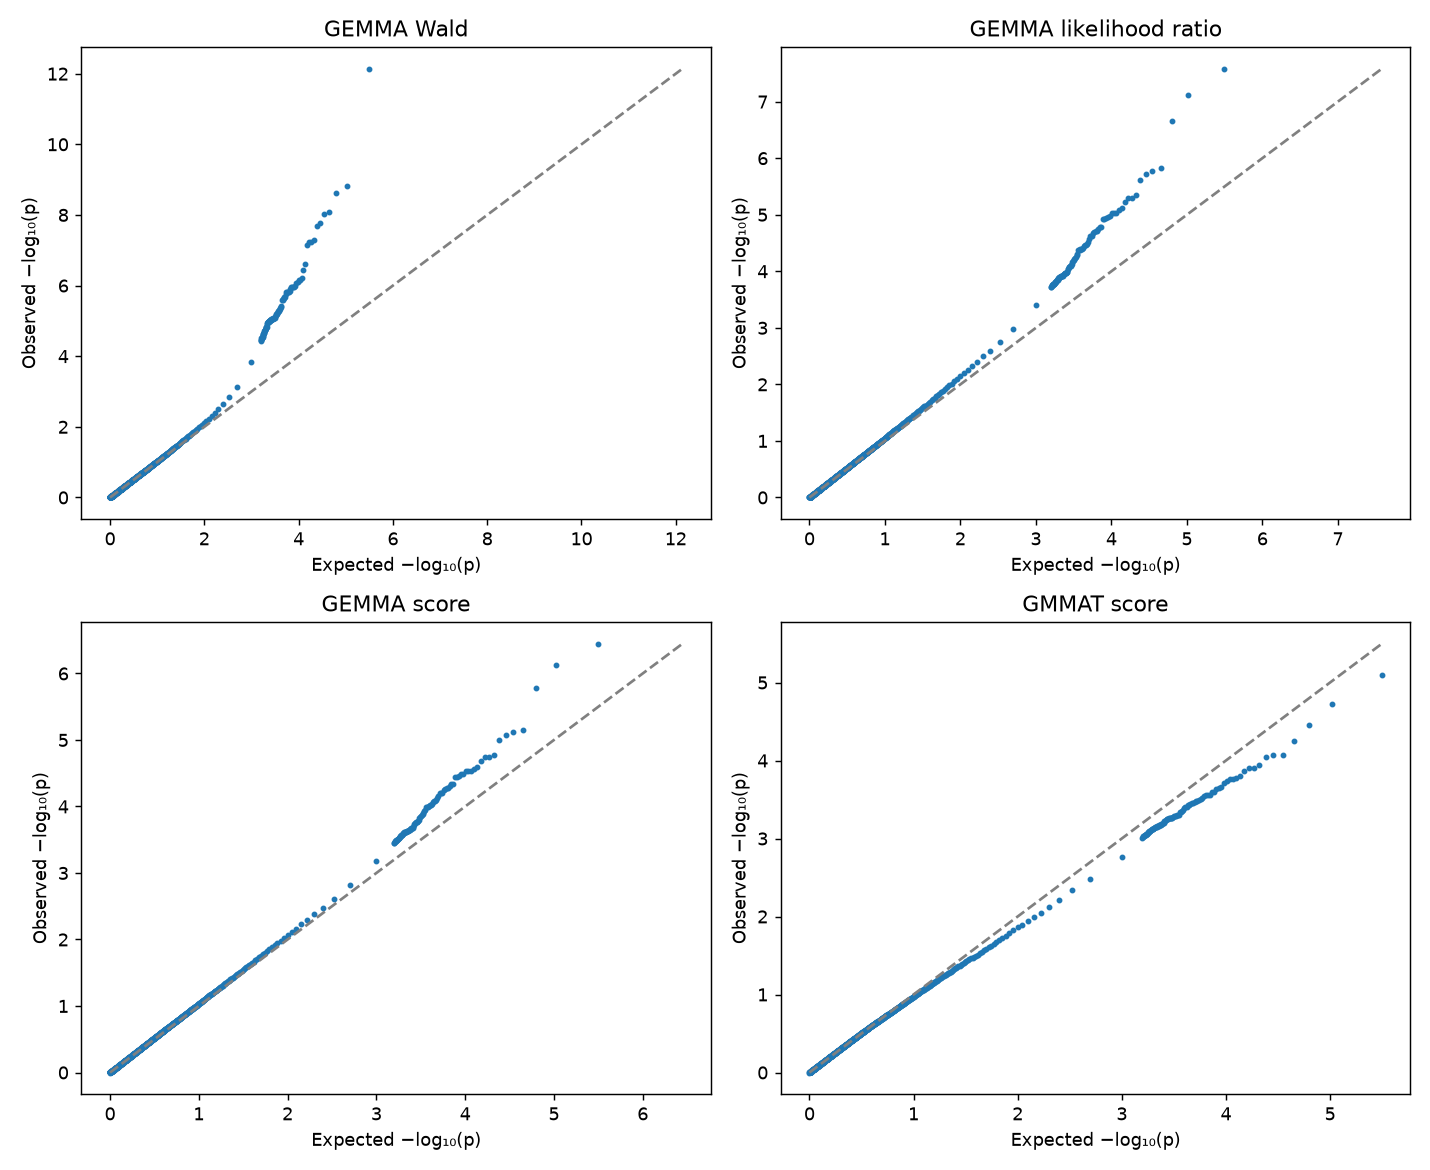

In [6]:
# Optionally run pooled models or rebuild their summaries, then check and display the saved pooled results.
# Fit diagnostics remain visible because pooling assumes a shared variance model.

# Fresh inference requires the WSL/Linux project kernel and native association tools.
# Progress is printed by scheme group and chromosome. Completed jobs are verified and reused.
run_pooled_models = False
if run_pooled_models:
#     run_script(study_root, "pooled_gwas.py", "--output", pooled_run, linux=True)
#     run_script(study_root, "check_pooled_inputs.py", linux=True)
    association_r = Path.home() / "anaconda3/envs/tsa2024-association/bin/Rscript"
#     subprocess.run([str(association_r), str(study_root / "scripts/check_pooled_scores.R"), str(study_root)], check=True)

# Rebuild figure summaries after completing inference; this does not refit models.
rebuild_pooled_summary = False
# if run_pooled_models or rebuild_pooled_summary or not (pooled_folder / "summary.private.json").exists():
#     run_script(study_root, "summarize_pooled.py", "--run-dir", pooled_run, "--results-dir", pooled_folder)
pooled = read_json(pooled_folder / "summary.private.json")
assert pooled["status"] == "exploratory_pooled_review_complete"
assert pooled["original_sources_unchanged"]
assert pooled["config_sha256"] == file_digest(study_root / "config/cross_breed.json")
assert read_json(pooled_run / "input-check.private.json")["status"] == "pooled_relationships_and_selected_inputs_verified"
assert read_json(pooled_run / "score-check.private.json")["status"] == "pooled_sample_orders_covariates_and_selected_scores_verified"
show_analysis_rows(pooled["analyses"])
lines = ['| Scheme | Converged GMMAT Chromosome Nulls | GEMMA ML Variance-Boundary Markers | Median χ² Ratio, Wald / GMMAT Score |',
         '| :---: | :---: | :---: | :---: |']
for group in pooled["groups"]:
    scheme = group["scenario"]
    nulls = sum(r["gmmat_null_converged"] for r in pooled["diagnostics"] if r["scenario"] == scheme)
    wald = next(r for r in pooled["analyses"] if r["scenario"] == scheme and r["analysis"] == "GEMMA Wald")
    score = next(r for r in pooled["analyses"] if r["scenario"] == scheme and r["analysis"] == "GMMAT score")
    lines.append(f"| {scheme_label(scheme)} | {nulls}/38 | {wald['gemma_mle_boundary_count']:,} | {wald['median_chi_square_ratio']:.3f} / {score['median_chi_square_ratio']:.3f} |")
display(Markdown("\n".join(lines)))
for group in pooled["groups"]:
    display(Markdown(f"### Scheme {scheme_label(group['scenario'])}: {group['dogs']} dogs, {group['cases']} cases"))
    for suffix in ["_manhattan.png", "_qq.png"]:
        display(Image(filename=str(pooled_folder / (group["scenario"] + suffix))))

### Interpretation
- Meta-analysis and pooling cannot repair uncertain breed fits.
- Schemes share cases, and all schemes retain small-sample and relatedness limitations.
- [Cross-breed methods](../docs/methods/08%20Cross-breed%20association.md) describe the calculations.